# Домашнее задание по нейросетям в скоринге.

**ФИО**: Класс Егор Аркадьевич

**Данные для обучения**: 
1. [Шардированные данные для нейросети](https://www.kaggle.com/datasets/ahm352/t-intensive-nn-sequence-shards)
2. [Признаки для обучения бустинга](https://www.kaggle.com/datasets/ahm352/t-intensive-features)

**Сдать нужно**: ссылку на Kaggle Notebook. Либо `.ipynb` с outputs ячеек. Воспроизводимость ноута -- большой плюс. Если нейронку обучали на других мощностях (не в kaggle), то можно сохранить модель в kaggle и добавить обученную модель через Input Kaggle для воспроизводимости. 

Если сложности с сохранением модели - нужно прикрепить `.parquet / .csv` с предсказаниями финальной версии модели

За каждый эксперимент по **1.5** балла. Максимум за тип эксперимента **3** балла. Для каждого эксперимента должна быть описана гипотеза и выводы. За невоспроизводимость/сильное переобучение/ без вывода будут штрафы.

Улучшение нейросети будем оценивать в **1** балл за каждое увеличение в **0.0075** auc бейзлайна нейросети. Например, качество улучшилось с `0.69 -> 0.707`. Это оцениваем в **2** балла. Максимум - **4** основных балла (тк качество бустинга **0.72** auc).

За каждое улучшение в **0.01 auc** сверху **0.72 auc** добавляем **1** балл. Максимум **3** балла.

Максимально можно получить **5** дополнительных баллов.

В итоге работы написать отчет с выводами проделанной работы. Интерпретация результатов, краткое описание проделанных экспериментов и идеи для дальнейшего развития этой модели.

## Разбалловка: 20 основных

| Основная часть | Баллы |
|---|---:|
| Воспроизводимость ноута / возможность инференса модели, если обучена не в Kaggle. Run All ячеек на подвыборке отрабатывает | 2 |
| EDA данных. Сформулированы гипотезы, инсайты для дальнейших экспериментов | 1.5 |
| ≥2 эксперимента с данными | 3 |
| ≥2 эксперимента с моделью (архитектурой) | 3 |
| ≥2 эксперимента с loss/обучением | 3 |
| Исследования с артефактами, есть learning curves, логирования в процессе обучения | 1.5 |
| Побито качество (harmonic mean auc) бустинга на тесте | 4 |
| Проинтерпретированы аттрибуты транзакции с помощью permutation importance | 2 |

| **Итого** | **20.00** |

| Бонус | Баллы |
|---|---:|
| Обучена нейросеть с головой для предсказания непрерывного таргета | 3 |
| Качество нейросети на тесте (по harmonic mean auc) с непрерывным таргетом не меньше исходной | 1 |
| Дополнительное улучшение качества нейросети | 3 |
| Пайплайн препроцессинг -> обучение/валидация -> эксперимент. Процесс тестирования экспериментов оформлен в виде шаблонизированного кода | 1.5 |
| Добавлен сервис логирования экспериментов (tensorboard/clearml) | 1 |
| Дополнительные методы интерпретации | 2 |
| **Максимум** | **11.5** |

Критерий **Обучена нейросеть с головой для предсказания непрерывного таргета**:
Необходимо составить самостоятельно таргет - сумму транзакций за последние 30 дней до даты заявки. Его будем считать непрерывным таргетом. Будем предсказывать этот таргет по транзакциям, которые были **до 30 дней** до заявки, чтобы не произвести даталик. 

Далее будет необходимо составить мультитаск нейросеть, которая будет предсказывать и дефолт и сумму транзакций за последние 30 дней.

Лосс, метрики выбираются самостоятельно. Но дополнительно надо измерить harmonic mean auc только по бинарным таргетам.

In [22]:
from pathlib import Path
import hashlib
import json
import random
import time
from dataclasses import dataclass

import numpy as np
import pandas as pd
import polars as pl

import torch
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

SEED = 42
MAX_SEQ_LEN, BATCH_SIZE, EPOCHS = 128, 256, 3

PREBUILT_DIR = Path(
    "/kaggle/input/datasets/ahm352/t-intensive-nn-sequence-shards"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Задание:

Обучить нейросеть с качеством (harmonic auc) выше бустинга на тесте: выше `0.721359`.

Датасет для обучения тут - https://www.kaggle.com/datasets/ahm352/t-intensive-nn-sequence-shards



In [23]:
with open("/kaggle/input/datasets/ahm352/t-intensive-nn-sequence-shards/preprocessing.json", "r", encoding="utf-8") as file:
    preprocessing = json.load(file)
with open("/kaggle/input/datasets/ahm352/t-intensive-nn-sequence-shards/manifest.json", "r", encoding="utf-8") as file:
    manifest = json.load(file)

In [24]:
from torch import nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
from torch.utils.data import IterableDataset, DataLoader
from torch.utils.tensorboard import SummaryWriter
import matplotlib.pyplot as plt
import seaborn as sns

STORED_CAT_COLS = list(preprocessing["categorical_columns"])
STORED_CONT_COLS = list(preprocessing["continuous_columns"])
# Остальные признаки оставлены для домашки.
CAT_COLS = ["operation_kind", "mcc", "income_flag"]
CONT_COLS = ["amnt", "days_before"]

missing = (set(CAT_COLS) - set(STORED_CAT_COLS)) | (
    set(CONT_COLS) - set(STORED_CONT_COLS)
)

if missing:
    raise ValueError(f"Baseline-колонки отсутствуют в Dataset: {sorted(missing)}")

CAT_INDICES = np.asarray([STORED_CAT_COLS.index(c) for c in CAT_COLS])
CONT_INDICES = np.asarray([STORED_CONT_COLS.index(c) for c in CONT_COLS])

vocab_specs = preprocessing["vocabularies"]

STORED_VOCAB_SIZES = {
    column: int(vocab_specs[column]["size"]) for column in STORED_CAT_COLS
}

VOCAB_SIZES = {column: STORED_VOCAB_SIZES[column] for column in CAT_COLS}

In [25]:
def product_harmonic_auc(y_true, score, product,
                         expected_products=None):
    """Return harmonic product AUC together with its auditable table.

    Parameters
    ----------
    y_true, score, product : array-like
        Aligned targets, model scores and product labels.
    expected_products : collection or None
        Products that must participate in the harmonic mean.

    Returns
    -------
    tuple[float, pandas.DataFrame]
        Harmonic mean and the underlying per-product AUC table.
    """
    table = product_auc_table(y_true, score, product, expected_products)
    return harmonic_mean_auc(table["auc"]), table

In [26]:
def harmonic_mean_auc(values):
    """Compute the harmonic mean of product-level ROC-AUC values.

    Parameters
    ----------
    values : array-like
        One ROC-AUC value for every evaluated product.

    Returns
    -------
    float
        ``P / sum(1 / auc_p)``. A zero product AUC makes the result zero.

    Raises
    ------
    ValueError
        If the collection is empty, non-finite or outside ``[0, 1]``.
    """
    scores = np.asarray(values, dtype="float64")
    if scores.ndim != 1 or len(scores) == 0 or not np.isfinite(scores).all():
        raise ValueError("Нужен непустой конечный вектор product AUC")
    if np.any((scores < 0) | (scores > 1)):
        raise ValueError("ROC-AUC должен находиться в [0, 1]")
    if np.any(scores == 0):
        return 0.0
    return float(len(scores) / np.reciprocal(scores).sum())

In [27]:
def product_auc_table(y_true, score, product, expected_products=None):
    """Calculate ROC-AUC independently for every product.

    Parameters
    ----------
    y_true : array-like
        Binary targets.
    score : array-like
        Positive-class probabilities or monotonic decision scores.
    product : array-like
        Product label for each observation.
    expected_products : collection or None
        Products that must all be present; omission is an error.

    Returns
    -------
    pandas.DataFrame
        Columns ``product``, ``n`` and ``auc``, sorted by product.

    Raises
    ------
    ValueError
        If lengths differ or a product contains only one target class.
    """
    target, score, product = map(np.asarray, (y_true, score, product))
    if not (len(target) == len(score) == len(product)):
        raise ValueError("target, score и product должны иметь одну длину")
    frame = pd.DataFrame({"target": target, "score": score, "product": product})
    observed = set(frame["product"].unique())
    if expected_products is not None and observed != set(expected_products):
        raise ValueError(f"Набор продуктов {observed} != {set(expected_products)}")
    rows = []
    for value, group in frame.groupby("product", sort=True):
        if group["target"].nunique() != 2:
            raise ValueError(f"product={value}: ROC-AUC требует оба класса")
        rows.append({"product": value, "n": len(group),
                     "auc": roc_auc_score(group["target"], group["score"])})
    return pd.DataFrame(rows)

In [28]:
REQUIRED_SHARD_KEYS = {"app_id", "offsets", "lengths", "cats", "cont",
                       "target", "product_idx"}


In [29]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [30]:

class NpzSequenceDataset(IterableDataset):
    """Stream selected baseline features from full pre-encoded NPZ shards."""
    def __init__(self, files, shuffle=False, seed=SEED):
        """Configure files and deterministic epoch shuffling.

        Parameters
        ----------
        files : iterable[pathlib.Path]
            Shards from one split and optional products.
        shuffle : bool
            Shuffle train files and applications.
        seed : int
            Base seed, incremented per iterator pass.
        """
        self.files = list(files)
        self.shuffle, self.seed, self.epoch = shuffle, seed, 0
    def __iter__(self):
        """Yield only columns selected by ``CAT_INDICES``/``CONT_INDICES``."""
        rng = np.random.default_rng(self.seed + self.epoch)
        files = list(self.files)
        if self.shuffle:
            rng.shuffle(files)
            self.epoch += 1
        for path in files:
            with np.load(path, allow_pickle=False) as archive:
                data = {key: archive[key] for key in REQUIRED_SHARD_KEYS}
            order = np.arange(len(data["lengths"]))
            if self.shuffle:
                rng.shuffle(order)
            for index in order:
                start, stop = data["offsets"][index:index + 2]
                cats = data["cats"][start:stop][:, CAT_INDICES]
                cont = data["cont"][start:stop][:, CONT_INDICES]
                yield (torch.from_numpy(cats).long(), torch.from_numpy(cont).float(),
                       int(data["lengths"][index]), float(data["target"][index]),
                       int(data["product_idx"][index]), int(data["app_id"][index]))

In [31]:
def collate(items):
    """Pad variable-length applications within one mini-batch.

    Parameters
    ----------
    items : list[tuple]
        Six-tuples emitted by ``NpzSequenceDataset``.

    Returns
    -------
    dict[str, torch.Tensor]
        Padded features plus original lengths, targets, products and IDs.
    """
    cats, cont, lengths, target, product, app_id = zip(*items)
    return {
        "cats": pad_sequence(cats, batch_first=True),
        "cont": pad_sequence(cont, batch_first=True),
        "length": torch.tensor(lengths),
        "target": torch.tensor(target, dtype=torch.float32),
        "product": torch.tensor(product, dtype=torch.long),
        "app_id": torch.tensor(app_id, dtype=torch.long),
    }

In [32]:
def shard_paths(split, product_indices=None):
    """Resolve manifest entries for one split and optional products.

    Parameters
    ----------
    split : {"train", "valid", "test"}
        Dataset subset to read.
    product_indices : collection[int] or None
        Product buckets; ``None`` selects every product.

    Returns
    -------
    list[pathlib.Path]
        Existing NPZ paths in deterministic order.
    """
    if split not in manifest["shards"]:
        raise ValueError(f"Неизвестный split: {split}")
    groups = manifest["shards"][split]
    keys = sorted(groups, key=int)
    if product_indices is not None:
        keys = [str(index) for index in sorted(product_indices)]
    files = [
        PREBUILT_DIR / entry["path"]
        for key in keys for entry in groups.get(key, [])
    ]
    missing = [path for path in files if not path.is_file()]
    if missing:
        raise FileNotFoundError(f"Не найдены shards: {missing[:3]}")
    if not files:
        raise ValueError(f"Нет shards для split={split}, products={keys}")
    return files


In [33]:
loaders = {}

for split_name in ["train", "valid", "test"]:
    dataset = NpzSequenceDataset(
        shard_paths(split_name),
        shuffle=(split_name == "train"),
    )
    loaders[split_name] = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        collate_fn=collate,
        pin_memory=(device.type == "cuda"),
    )

In [34]:
class MultiHeadLSTM(nn.Module):
    """Shared transaction encoder with one binary head per product."""
    def __init__(self, vocab_sizes, n_cont, n_products, emb_dim=12, hidden=64):
        """Construct embeddings, shared LSTM and product heads.
        Parameters
        ----------
        vocab_sizes : dict[str, int]
            Embedding sizes including PAD=0 and UNK=1.
        n_cont, n_products : int
            Continuous feature count and number of heads.
        emb_dim, hidden : int
            Embedding and LSTM hidden widths.
        """
        super().__init__()
        self.embeddings = nn.ModuleList([
            nn.Embedding(vocab_sizes[name], emb_dim, padding_idx=0)
            for name in CAT_COLS
        ])
        width = emb_dim * len(CAT_COLS) + n_cont
        self.encoder = nn.LSTM(width, hidden, batch_first=True)
        self.dropout = nn.Dropout(0.2)
        self.heads = nn.ModuleList([nn.Linear(hidden, 1)
                                    for _ in range(n_products)])
    def forward(self, cats, cont, lengths, product):
        """Encode histories and return each row's selected-head logit.

        Batch-first inputs are packed, so padding cannot alter the final
        shared state. The returned tensor has shape ``(B,)``.
        """
        embedded = [layer(cats[:, :, index])
                    for index, layer in enumerate(self.embeddings)]
        sequence = torch.cat([*embedded, cont], dim=-1)
        packed = pack_padded_sequence(
            sequence, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden, _) = self.encoder(packed)
        logits = torch.cat([head(self.dropout(hidden[-1]))
                            for head in self.heads], dim=1)
        return logits.gather(1, product[:, None]).squeeze(1)

In [35]:
def summed_product_bce(logits, target, product):
    """Sum mean binary cross-entropy over products present in a step.

    Parameters
    ----------
    logits, target : torch.Tensor
        Aligned one-dimensional model outputs and binary labels.
    product : torch.Tensor
        Integer product-head index for every row.

    Returns
    -------
    torch.Tensor
        Scalar ``sum_p mean(BCE_i | product_i=p)``.
    """
    if not (logits.ndim == target.ndim == product.ndim == 1):
        raise ValueError("logits, target и product должны быть векторами")
    if not (len(logits) == len(target) == len(product)) or len(logits) == 0:
        raise ValueError("Векторы loss должны иметь одну ненулевую длину")
    element_loss = nn.functional.binary_cross_entropy_with_logits(
        logits, target, reduction="none"
    )
    product_losses = [element_loss[product == index].mean()
                      for index in torch.unique(product, sorted=True)]
    return torch.stack(product_losses).sum()

In [36]:
product_values = preprocessing["product_values"]

In [37]:
model = MultiHeadLSTM(
    VOCAB_SIZES, len(CONT_COLS), len(product_values)
).to(device)

In [38]:
@torch.no_grad()
def evaluate(model, loader, expected_products=None):
    """Evaluate summed product BCE and harmonic product ROC-AUC.

    Parameters
    ----------
    model : torch.nn.Module
        Model compatible with batches returned by ``collate``.
    loader : torch.utils.data.DataLoader
        Validation or test sequence loader.
    expected_products : collection or None
        Product labels that must all be present in the split.

    Returns
    -------
    tuple
        Loss, H-AUC, targets, probabilities, app IDs and product labels.
    """
    model.eval()
    logits_all, targets, product_indices, application_ids = [], [], [], []
    for batch in loader:
        logits = model(
            batch["cats"].to(device), batch["cont"].to(device),
            batch["length"], batch["product"].to(device),
        )
        logits_all.append(logits.cpu())
        targets.append(batch["target"])
        product_indices.append(batch["product"])
        application_ids.append(batch["app_id"])
    logits = torch.cat(logits_all)
    target = torch.cat(targets)
    product_index = torch.cat(product_indices)
    loss = summed_product_bce(logits, target, product_index).item()
    probabilities = torch.sigmoid(logits).numpy()
    product = np.asarray(product_values)[product_index.numpy()]
    metric, _ = product_harmonic_auc(
        target.numpy(), probabilities, product, expected_products
    )
    return (loss, metric, target.numpy(), probabilities,
            torch.cat(application_ids).numpy(), product)

In [39]:
def train_one_epoch(model, loader, optimizer):
    model.train()
    losses = []

    for batch in loader:
        optimizer.zero_grad(set_to_none=True)

        logits = model(
            batch["cats"].to(device),
            batch["cont"].to(device),
            batch["length"],
            batch["product"].to(device),
        )
        target = batch["target"].to(device)
        product = batch["product"].to(device)

        loss = summed_product_bce(logits, target, product)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        losses.append(loss.item())

    return float(np.mean(losses))

In [40]:
def train_model(model, train_loader, valid_loader,
                epochs, run_name, lr=2e-3):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", patience=1, factor=0.5
    )

    checkpoint_path = Path("/kaggle/working") / f"{run_name}_best.pt"
    best_auc = -np.inf
    history = []

    for epoch in range(1, epochs + 1):
        started = time.perf_counter()
        print(f"Epoch {epoch}/{epochs}")

        train_loss = train_one_epoch(model, train_loader, optimizer)
        val_loss, val_auc, *_ = evaluate(model, valid_loader)
        scheduler.step(val_auc)

        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_hmean_auc": val_auc,
            "lr": optimizer.param_groups[0]["lr"],
            "seconds": time.perf_counter() - started,
        }
        history.append(row)

        print(
            f"Epoch {epoch}/{epochs}: "
            f"train_loss={train_loss:.4f}, "
            f"val_loss={val_loss:.4f}, "
            f"val_hmean_auc={val_auc:.6f}"
        )

        if val_auc > best_auc:
            best_auc = val_auc
            torch.save(model.state_dict(), checkpoint_path)

    model.load_state_dict(
        torch.load(checkpoint_path, map_location=device, weights_only=True)
    )
    return pd.DataFrame(history)

In [41]:
model

MultiHeadLSTM(
  (embeddings): ModuleList(
    (0): Embedding(9, 12, padding_idx=0)
    (1): Embedding(110, 12, padding_idx=0)
    (2): Embedding(5, 12, padding_idx=0)
  )
  (encoder): LSTM(38, 64, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (heads): ModuleList(
    (0-4): 5 x Linear(in_features=64, out_features=1, bias=True)
  )
)

Epoch 1/3
Epoch 1/3: train_loss=0.1611, val_loss=0.7496, val_hmean_auc=0.583181
Epoch 2/3
Epoch 2/3: train_loss=0.1441, val_loss=0.6997, val_hmean_auc=0.662108
Epoch 3/3
Epoch 3/3: train_loss=0.1392, val_loss=0.6932, val_hmean_auc=0.674826


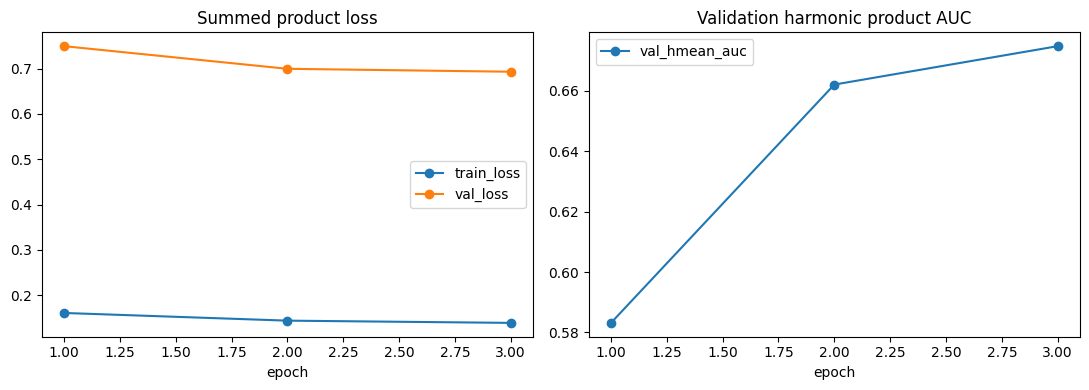

In [42]:
history = train_model(
    model, loaders['train'], loaders["valid"], EPOCHS, "main"
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
history.plot(x="epoch", y=["train_loss", "val_loss"], marker="o",
             ax=axes[0], title="Summed product loss")
history.plot(x="epoch", y="val_hmean_auc", marker="o", ax=axes[1],
             title="Validation harmonic product AUC")
plt.tight_layout()


## Оценивание качества



In [43]:
features = pd.read_parquet("/kaggle/input/datasets/ahm352/t-intensive-features")

In [44]:
features

,app_id,product,COUNT(transactions),MAX(transactions.amnt),MAX(transactions.days_before),MAX(transactions.hour_diff),MAX(transactions.transaction_number),MEAN(transactions.amnt),MEAN(transactions.days_before),MEAN(transactions.hour_diff),...,STD(transactions.amnt),STD(transactions.days_before),STD(transactions.hour_diff),STD(transactions.transaction_number),SUM(transactions.amnt),SUM(transactions.days_before),SUM(transactions.hour_diff),SUM(transactions.transaction_number),flag,split
0,2,1,229,0.496822,351.0,875.0,229.0,0.306107,171.196507,36.655022,...,0.087890,96.796770,84.381177,66.250786,70.098407,39204.0,8394.0,26335.0,0,valid
1,5,1,90,0.594620,352.0,1943.0,90.0,0.401968,126.333333,91.955556,...,0.096075,105.088299,213.870323,26.124701,36.177086,11370.0,8276.0,4095.0,0,valid
2,6,1,260,0.686218,359.0,455.0,260.0,0.413805,202.861538,32.984615,...,0.106790,90.061048,83.360221,75.199734,107.589377,52744.0,8576.0,33930.0,0,train
3,7,0,91,0.476811,359.0,671.0,91.0,0.305449,157.219780,93.604396,...,0.091558,102.827342,157.927190,26.413380,27.795857,14307.0,8518.0,4186.0,0,test
4,8,2,26,0.539584,79.0,462.0,26.0,0.383976,41.846154,64.384615,...,0.081964,24.556372,125.261032,7.648529,9.983374,1088.0,1674.0,351.0,0,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
599995,1003044,1,260,0.638027,359.0,969.0,260.0,0.311101,214.230769,31.030769,...,0.097321,92.287451,93.914562,75.199734,80.886324,55700.0,8068.0,33930.0,0,train
599996,1003045,1,55,0.588211,344.0,843.0,55.0,0.451358,206.600000,146.400000,...,0.076019,95.496674,238.910536,16.020820,24.824672,11363.0,8052.0,1540.0,0,train
599997,1003047,0,260,0.661614,359.0,370.0,260.0,0.440434,185.080769,32.896154,...,0.099036,98.999967,58.307208,75.199734,114.512897,48121.0,8553.0,33930.0,0,train
599998,1003048,1,219,0.684931,359.0,1245.0,219.0,0.420723,121.292237,39.246575,...,0.103740,106.029408,118.453155,63.364028,92.138302,26563.0,8595.0,24090.0,0,valid


In [45]:
test_mask = features['split'] == 'test'

In [46]:
_, LSTM_FULL_HMEAN_AUC, lstm_y, lstm_p, lstm_ids, lstm_product = evaluate(
    model, loaders["test"], product_values
)
predictions = pd.DataFrame({"app_id": lstm_ids, "target": lstm_y,
                            "product": lstm_product, "probability": lstm_p})

boost_test_ids = set(features.loc[test_mask, "app_id"])

common = predictions[predictions["app_id"].isin(boost_test_ids)]

if len(common) != len(boost_test_ids):
    raise ValueError("Не все CatBoost test app_id найдены в LSTM shards")

boost_common = features.loc[test_mask, ["app_id", "product", "flag"]].copy()

same_test = boost_common.merge(
    common.rename(columns={"probability": "lstm_probability"}),
    on=["app_id", "product"], validate="one_to_one",
)

lstm_table = product_auc_table(
    same_test["target"], same_test["lstm_probability"], same_test["product"],
    product_values,
).rename(columns={"auc": "lstm_auc"}).drop(columns="n")

print(f"LSTM full-test harmonic product AUC: {LSTM_FULL_HMEAN_AUC:.6f}")

LSTM full-test harmonic product AUC: 0.678964


In [47]:
print("Категориальные признаки:", STORED_CAT_COLS)
print("Числовые признаки:", STORED_CONT_COLS)

Категориальные признаки: ['currency', 'operation_kind', 'card_type', 'operation_type', 'operation_type_group', 'ecommerce_flag', 'payment_system', 'income_flag', 'mcc', 'country', 'city', 'mcc_category', 'day_of_week', 'hour', 'weekofyear']
Числовые признаки: ['amnt', 'days_before', 'hour_diff', 'transaction_number']


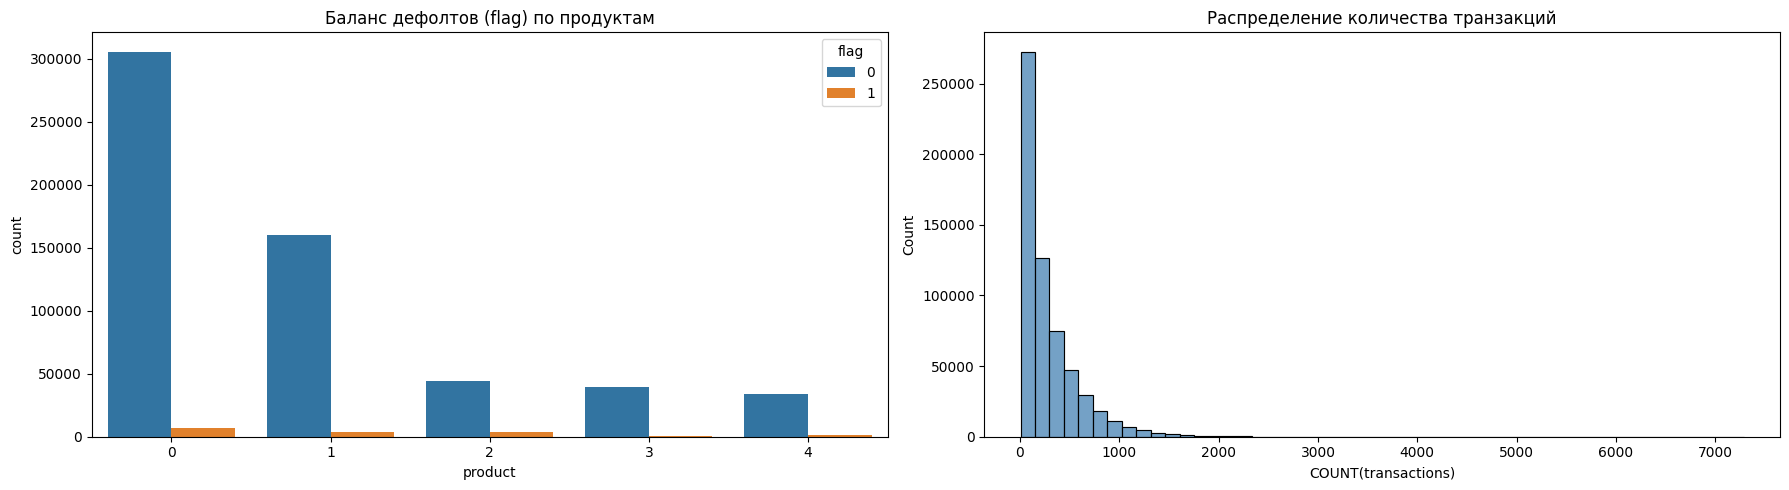

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

sns.countplot(data=features, x='product', hue='flag', ax=axes[0])
axes[0].set_title("Баланс дефолтов (flag) по продуктам")

sns.histplot(features['COUNT(transactions)'], bins=50, ax=axes[1], color='steelblue')
axes[1].set_title("Распределение количества транзакций")

plt.tight_layout()
plt.show()

,product,total_clients,defaults,default_rate,median_transactions,mean_amnt
0,0,312901,7145,0.02,168.0,0.383484
1,1,164013,4105,0.03,219.0,0.380994
2,2,47614,3363,0.07,105.0,0.354274
3,3,40140,796,0.02,301.0,0.376038
4,4,35332,1135,0.03,110.0,0.390866


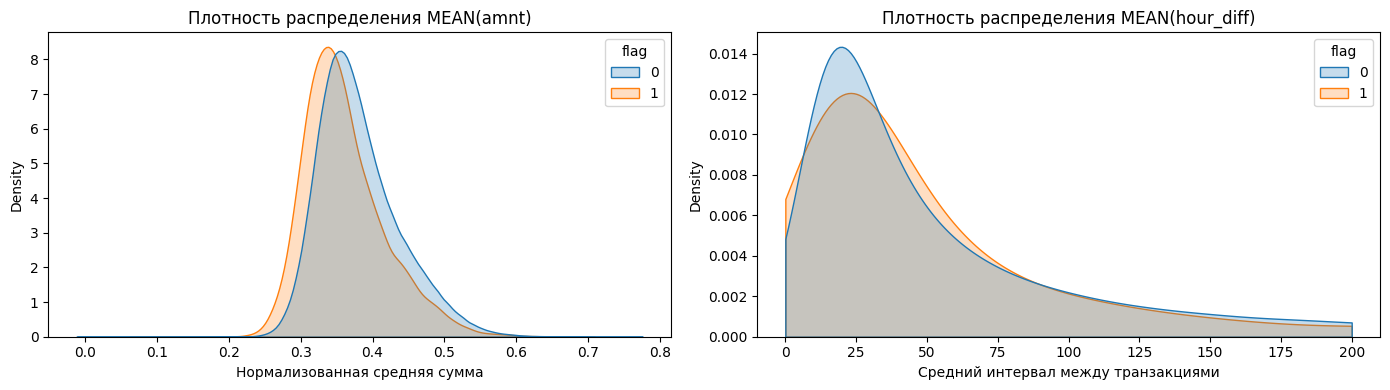

In [49]:
eda_summary = features.groupby("product").agg(
    total_clients=("flag", "count"),
    defaults=("flag", "sum"),
    default_rate=("flag", lambda x: round(x.mean(), 2)),
    median_transactions=("COUNT(transactions)", "median"),
    mean_amnt=("MEAN(transactions.amnt)", "mean")
).reset_index()

display(eda_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.kdeplot(data=features, x='MEAN(transactions.amnt)', hue='flag', 
            common_norm=False, fill=True, clip=(-1, 2), ax=axes[0])
axes[0].set_title("Плотность распределения MEAN(amnt)")
axes[0].set_xlabel("Нормализованная средняя сумма")

sns.kdeplot(data=features, x='MEAN(transactions.hour_diff)', hue='flag', 
            common_norm=False, fill=True, clip=(0, 200), ax=axes[1])
axes[1].set_title("Плотность распределения MEAN(hour_diff)")
axes[1].set_xlabel("Средний интервал между транзакциями")

plt.tight_layout()
plt.show()

Наблюдения из данных:
- Баланс классов в таргете сильно не равномерен
- Видим разное поведение по разным продуктам
- Плотность распределения для дефолтников в признаке amnt смещена относительно прибыльных клиентов. Признак должен быть полезен.
- Также и с интервалами между транзакциями мы видим перекос небольшой в малую задержку между транзакциями. Признак следует добавить.


Гипотезы:
- Добавление признаков для контекста транзакций может улучшить метрику `hour_diff`, `transaction_number`.
- Тажке учет категориальных признаков для отслеживание сезонности и флаг категории покупки могут оказаться полезными (`hour`, `mcc_category`, `ecommerce_flag`)
- Из-за дисбаланса классов текущий лосс может быть не сильно эффективен, и возможно нужно будет попробывать перейти к взвешанному
- Также нужно будет попробывать поменять разные параметры и попробывать механизм внимания.

Напишем функцию build_dataloaders для добавления признаков новых и измениния batch_size

In [50]:
CATBOOST_H_AUC = 0.721359


def build_dataloaders(cat_cols, cont_cols, batch_size=BATCH_SIZE):
    global CAT_COLS, CONT_COLS, CAT_INDICES, CONT_INDICES, VOCAB_SIZES
    
    CAT_COLS = list(cat_cols)
    CONT_COLS = list(cont_cols)
    CAT_INDICES = np.asarray([STORED_CAT_COLS.index(c) for c in CAT_COLS])
    CONT_INDICES = np.asarray([STORED_CONT_COLS.index(c) for c in CONT_COLS])
    VOCAB_SIZES = {column: STORED_VOCAB_SIZES[column] for column in CAT_COLS}
    
    loaders_dict = {}
    for split_name in ["train", "valid", "test"]:
        dataset = NpzSequenceDataset(
            shard_paths(split_name),
            shuffle=(split_name == "train"),
        )
        loaders_dict[split_name] = DataLoader(
            dataset,
            batch_size=batch_size,
            collate_fn=collate,
            pin_memory=(device.type == "cuda"),
        )
    return loaders_dict

In [51]:
def plot_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    history.plot(x="epoch", y=["train_loss", "val_loss"], marker="o",
                 ax=axes[0], title="Summed product loss")
    history.plot(x="epoch", y="val_hmean_auc", marker="o", ax=axes[1],
                 title="Validation harmonic product AUC")
    plt.tight_layout()
    plt.show()

Шаблон для далнейших эксперементов

In [52]:
def run_experiment(
    exp_name: str,
    cat_cols: list,
    cont_cols: list,
    model_class: type,
    model_kwargs: dict = None,
    epochs: int = EPOCHS,
    lr: float = 2e-3,
    loss_fn = summed_product_bce,
    batch_size: int = BATCH_SIZE
):
    
    if model_kwargs is None:
        model_kwargs = {}

    print("=" * 50)
    print(f"Эксперимент: {exp_name}")
    print("=" * 50)

    loaders = build_dataloaders(cat_cols, cont_cols, batch_size=batch_size)

    model = model_class(
        vocab_sizes=VOCAB_SIZES,
        n_cont=len(CONT_COLS),
        n_products=len(product_values),
        **model_kwargs
    ).to(device)

    history = train_model(
        model=model,
        train_loader=loaders["train"],
        valid_loader=loaders["valid"],
        epochs=epochs,
        run_name=exp_name,
        lr=lr,
        loss_fn=loss_fn
    )

    test_loss, test_auc, *_ = evaluate(model, loaders["test"], product_values)
    diff = test_auc - CATBOOST_H_AUC

    print("=" * 50)
    print(f"{exp_name} итоги:")
    print(f"Test H-AUC:     {test_auc:.6f}")
    print(f"CatBoost H-AUC: {CATBOOST_H_AUC:.6f}")
    print(f"Diff: {diff:+.6f} ({'Побито' if diff > 0 else 'Ниже бустинга'})")
    print("=" * 50)

    plot_history(history)

    return {
        "name": exp_name,
        "model": model,
        "history": history,
        "loaders": loaders,
        "test_auc": test_auc
    }

Немного подправим для будущего добавления другого лосса

In [55]:
def train_one_epoch(model, loader, optimizer, loss_fn=summed_product_bce):
    model.train()
    losses = []

    for batch in loader:
        optimizer.zero_grad(set_to_none=True)

        logits = model(
            batch["cats"].to(device),
            batch["cont"].to(device),
            batch["length"],
            batch["product"].to(device),
        )
        target = batch["target"].to(device)
        product = batch["product"].to(device)

        loss = loss_fn(logits, target, product)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        losses.append(loss.item())

    return float(np.mean(losses))


def train_model(model, train_loader, valid_loader,
                epochs, run_name, lr=2e-3, loss_fn=summed_product_bce):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", patience=1, factor=0.5
    )

    checkpoint_path = Path("/kaggle/working") / f"{run_name}_best.pt"
    best_auc = -np.inf
    history = []

    for epoch in range(1, epochs + 1):
        started = time.perf_counter()
        print(f"Epoch {epoch}/{epochs}")

        train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn=loss_fn)
        val_loss, val_auc, *_ = evaluate(model, valid_loader)
        scheduler.step(val_auc)

        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_hmean_auc": val_auc,
            "lr": optimizer.param_groups[0]["lr"],
            "seconds": time.perf_counter() - started,
        }
        history.append(row)

        print(
            f"Epoch {epoch}/{epochs}: "
            f"train_loss={train_loss:.4f}, "
            f"val_loss={val_loss:.4f}, "
            f"val_hmean_auc={val_auc:.6f}"
        )

        if val_auc > best_auc:
            best_auc = val_auc
            torch.save(model.state_dict(), checkpoint_path)

    model.load_state_dict(
        torch.load(checkpoint_path, map_location=device, weights_only=True)
    )
    return pd.DataFrame(history)

# Эксперемент №1.1
Добавление числовых признаков

Эксперимент: exp1_1_numeric_features
Epoch 1/3
Epoch 1/3: train_loss=0.1588, val_loss=0.7430, val_hmean_auc=0.619108
Epoch 2/3
Epoch 2/3: train_loss=0.1418, val_loss=0.6949, val_hmean_auc=0.672887
Epoch 3/3
Epoch 3/3: train_loss=0.1385, val_loss=0.6871, val_hmean_auc=0.688539
exp1_1_numeric_features итоги:
Test H-AUC:     0.686216
CatBoost H-AUC: 0.721359
Diff: -0.035143 (Ниже бустинга)


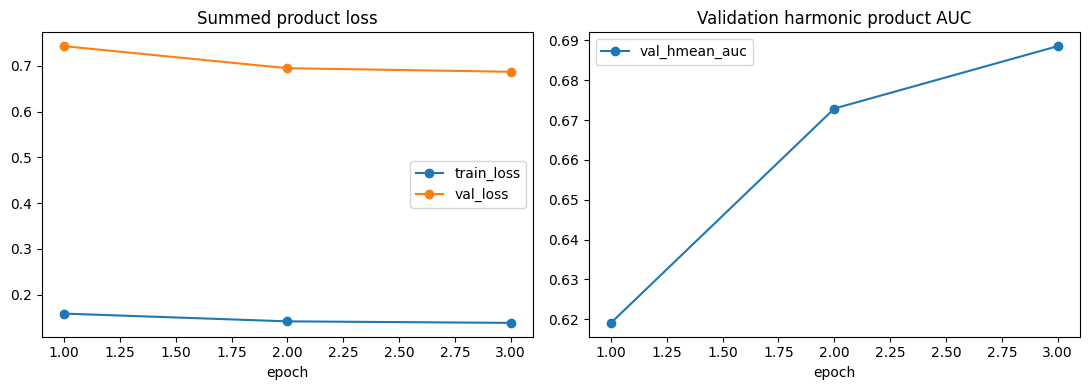

In [56]:
exp1_1_cats = ["operation_kind", "mcc", "income_flag"]
exp1_1_conts = ["amnt", "days_before", "hour_diff", "transaction_number"]

res_exp1_1 = run_experiment(
    exp_name="exp1_1_numeric_features",
    cat_cols=exp1_1_cats,
    cont_cols=exp1_1_conts,
    model_class=MultiHeadLSTM,
    epochs=EPOCHS
)

# Эксперимент №1.2 
Добавление категориальных признаков

In [57]:
print("Категориальные признаки:", STORED_CAT_COLS)

Категориальные признаки: ['currency', 'operation_kind', 'card_type', 'operation_type', 'operation_type_group', 'ecommerce_flag', 'payment_system', 'income_flag', 'mcc', 'country', 'city', 'mcc_category', 'day_of_week', 'hour', 'weekofyear']


Эксперимент: exp1_2_cats_features
Epoch 1/3
Epoch 1/3: train_loss=0.1574, val_loss=0.7331, val_hmean_auc=0.621433
Epoch 2/3
Epoch 2/3: train_loss=0.1421, val_loss=0.6968, val_hmean_auc=0.671376
Epoch 3/3
Epoch 3/3: train_loss=0.1383, val_loss=0.6865, val_hmean_auc=0.685715
exp1_2_cats_features итоги:
Test H-AUC:     0.693463
CatBoost H-AUC: 0.721359
Diff: -0.027896 (Ниже бустинга)


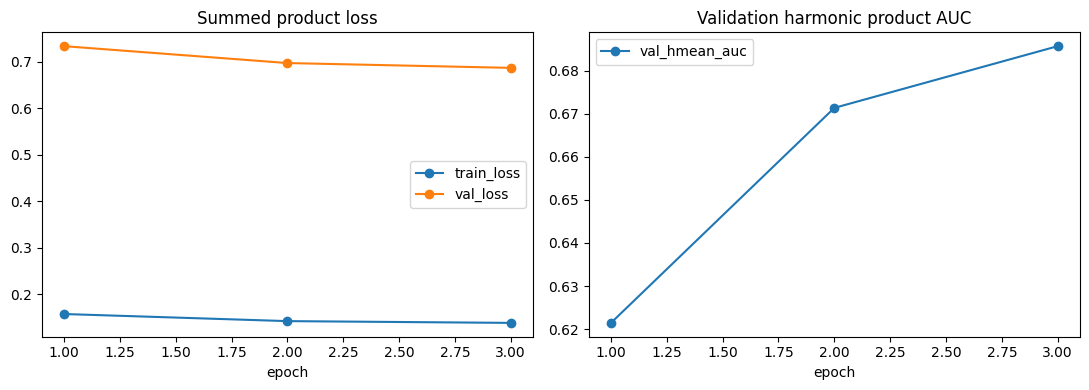

In [58]:
exp1_2_cats = [
    "operation_kind", "mcc", "income_flag",
    "mcc_category", "ecommerce_flag", "operation_type_group",
    "day_of_week", "hour"
]
exp1_2_conts = ["amnt", "days_before", "hour_diff", "transaction_number"]

res_exp1_2 = run_experiment(
    exp_name="exp1_2_cats_features",
    cat_cols=exp1_2_cats,
    cont_cols=exp1_2_conts,
    model_class=MultiHeadLSTM,
    epochs=EPOCHS
)

In [59]:
def make_permuted_collate(col_name, is_cat=True):
    """Обертка над collate: перемешивает значения выбранной колонки внутри батча."""
    def permuted_collate(items):
        batch = collate(items)
        if is_cat:
            col_idx = CAT_COLS.index(col_name)
            flat = batch["cats"][:, :, col_idx].reshape(-1)
            perm = torch.randperm(flat.size(0))
            batch["cats"][:, :, col_idx] = flat[perm].reshape(batch["cats"][:, :, col_idx].shape)
        else:
            col_idx = CONT_COLS.index(col_name)
            flat = batch["cont"][:, :, col_idx].reshape(-1)
            perm = torch.randperm(flat.size(0))
            batch["cont"][:, :, col_idx] = flat[perm].reshape(batch["cont"][:, :, col_idx].shape)
        return batch
    return permuted_collate


def compute_permutation_importance(model, dataset_test, cat_cols, cont_cols, base_auc):
    """Поочередно перемешивает каждый признак через DataLoader и замеряет падение H-AUC."""
    importance = {}
    
    print("Расчёт для категориальных признаков:")
    for col in cat_cols:
        loader = DataLoader(
            dataset_test, 
            batch_size=BATCH_SIZE, 
            shuffle=False, 
            collate_fn=make_permuted_collate(col, is_cat=True)
        )
        _, perm_auc, *_ = evaluate(model, loader, product_values)
        drop = max(0.0, base_auc - perm_auc)
        importance[col] = drop
        print(f" {col}: diff H-AUC: {drop:.6f}")

    print("\nРасчёт для числовых признаков:")
    for col in cont_cols:
        loader = DataLoader(
            dataset_test, 
            batch_size=BATCH_SIZE, 
            shuffle=False, 
            collate_fn=make_permuted_collate(col, is_cat=False)
        )
        _, perm_auc, *_ = evaluate(model, loader, product_values)
        drop = max(0.0, base_auc - perm_auc)
        importance[col] = drop
        print(f" {col}: diff H-AUC: {drop:.6f}")

    return pd.Series(importance).sort_values(ascending=True)

Базовый Test H-AUC: 0.693463
Расчёт для категориальных признаков:
 operation_kind: diff H-AUC: 0.015175
 operation_type_group: diff H-AUC: 0.000268
 mcc: diff H-AUC: 0.019553
 income_flag: diff H-AUC: 0.003626
 mcc_category: diff H-AUC: 0.017125
 ecommerce_flag: diff H-AUC: 0.000237
 operation_type_group: diff H-AUC: 0.000758
 day_of_week: diff H-AUC: 0.000885
 hour: diff H-AUC: 0.012791

Расчёт для числовых признаков:
 amnt: diff H-AUC: 0.019559
 days_before: diff H-AUC: 0.003014
 hour_diff: diff H-AUC: 0.024416
 transaction_number: diff H-AUC: 0.000540


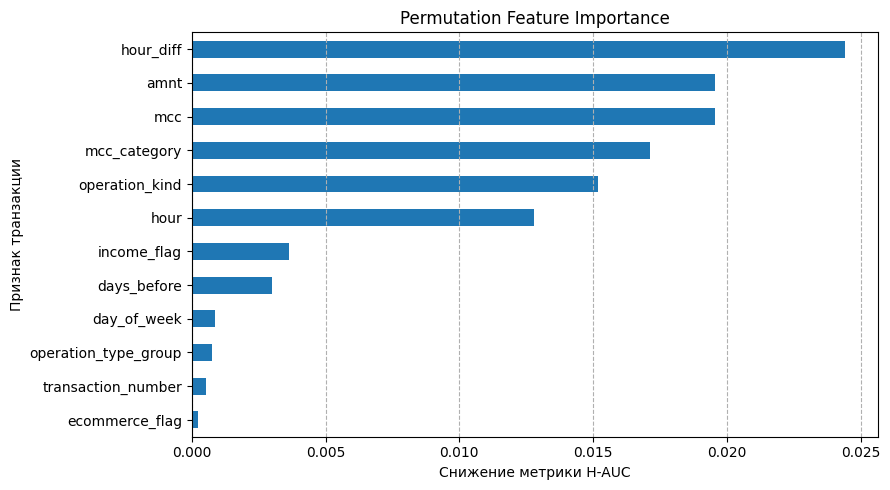

In [60]:
test_loader = res_exp1_2["loaders"]["test"]
base_test_auc = res_exp1_2["test_auc"]

test_dataset = NpzSequenceDataset(shard_paths("test"), shuffle=False)

print(f"Базовый Test H-AUC: {base_test_auc:.6f}\n" + "=" * 50)

importance_series = compute_permutation_importance(
    model=res_exp1_2['model'],
    dataset_test=test_dataset,
    cat_cols=CAT_COLS,
    cont_cols=CONT_COLS,
    base_auc=base_test_auc
)

plt.figure(figsize=(9, 5))
importance_series.plot(kind="barh")
plt.title("Permutation Feature Importance")
plt.xlabel("Снижение метрики H-AUC")
plt.ylabel("Признак транзакции")
plt.grid(axis="x", linestyle="--")
plt.tight_layout()
plt.show()

Уберем последние 3 признака

Эксперимент: exp1_2_cats_features
Epoch 1/3
Epoch 1/3: train_loss=0.1619, val_loss=0.7460, val_hmean_auc=0.583567
Epoch 2/3
Epoch 2/3: train_loss=0.1429, val_loss=0.6954, val_hmean_auc=0.670271
Epoch 3/3
Epoch 3/3: train_loss=0.1382, val_loss=0.6887, val_hmean_auc=0.687670
exp1_2_cats_features итоги:
Test H-AUC:     0.697557
CatBoost H-AUC: 0.721359
Diff: -0.023802 (Ниже бустинга)


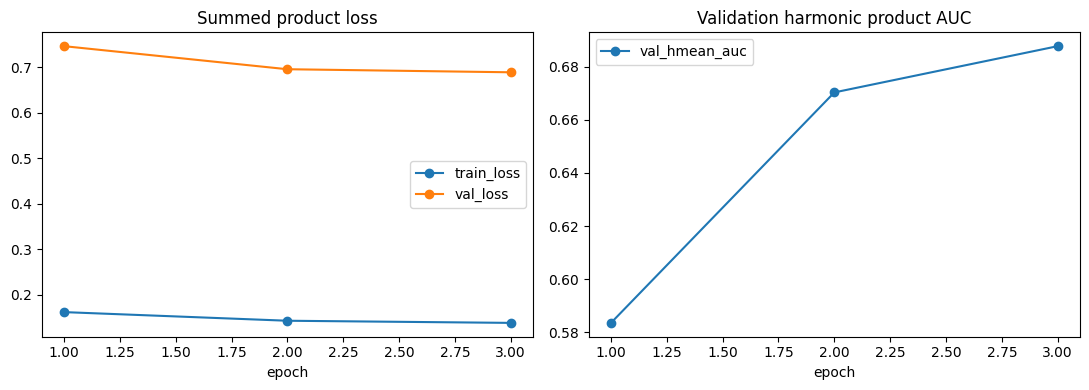

In [61]:
exp1_2_cats = [
    "operation_kind", "mcc", "income_flag",
    "mcc_category", "operation_type_group",
    "day_of_week", "hour"
]
exp1_2_conts = ["amnt", "days_before", "hour_diff"]

res_exp1_2 = run_experiment(
    exp_name="exp1_2_cats_features",
    cat_cols=exp1_2_cats,
    cont_cols=exp1_2_conts,
    model_class=MultiHeadLSTM,
    epochs=EPOCHS
)

# Эксперемент №2.1
Добавим один слой в нашу базовую модели LSTM

In [62]:
class MultiHeadDeepLSTM(nn.Module):
    """2-Layer LSTM"""
    def __init__(self, vocab_sizes, n_cont, n_products, emb_dim=12, hidden=64):
        super().__init__()
        self.embeddings = nn.ModuleList([
            nn.Embedding(vocab_sizes[name], emb_dim, padding_idx=0)
            for name in CAT_COLS
        ])
        width = emb_dim * len(CAT_COLS) + n_cont
        
        self.encoder = nn.LSTM(
            width, 
            hidden, 
            num_layers=2, 
            dropout=0.2, 
            batch_first=True
        )
        self.dropout = nn.Dropout(0.2)
        self.heads = nn.ModuleList([nn.Linear(hidden, 1) for _ in range(n_products)])

    def forward(self, cats, cont, lengths, product):
        embedded = [layer(cats[:, :, index]) for index, layer in enumerate(self.embeddings)]
        sequence = torch.cat([*embedded, cont], dim=-1)
        
        packed = pack_padded_sequence(
            sequence, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden, _) = self.encoder(packed)
        
        logits = torch.cat([head(self.dropout(hidden[-1])) for head in self.heads], dim=1)
        return logits.gather(1, product[:, None]).squeeze(1)

Эксперимент: 2-Layer_lstm
Epoch 1/3
Epoch 1/3: train_loss=0.1592, val_loss=0.7564, val_hmean_auc=0.573773
Epoch 2/3
Epoch 2/3: train_loss=0.1436, val_loss=0.6950, val_hmean_auc=0.676874
Epoch 3/3
Epoch 3/3: train_loss=0.1383, val_loss=0.6900, val_hmean_auc=0.689430
2-Layer_lstm итоги:
Test H-AUC:     0.697967
CatBoost H-AUC: 0.721359
Diff: -0.023392 (Ниже бустинга)


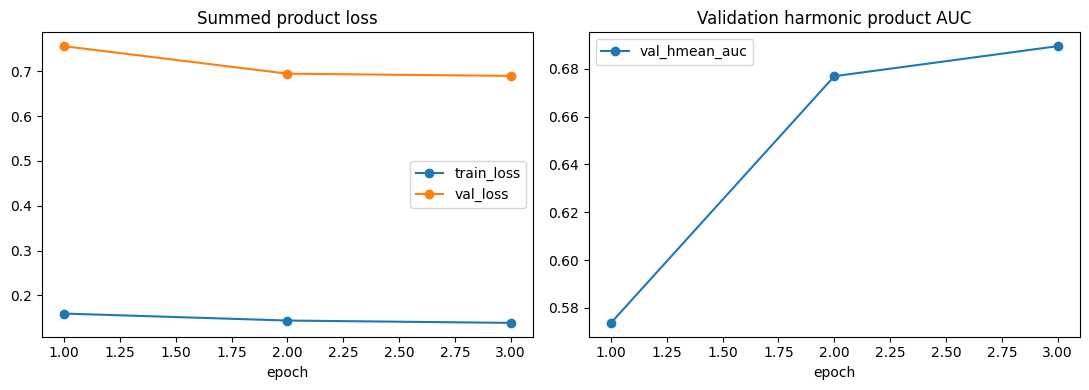

In [64]:
res_exp2_1 = run_experiment(
    exp_name="2-Layer_lstm",
    cat_cols=exp1_2_cats,
    cont_cols=exp1_2_conts,
    model_class=MultiHeadDeepLSTM,
    epochs=EPOCHS
)

# Эксперемент №2.2
- Добавим механизм внимания, вместо извелечения одного конечного вектора. 
- Заменим энкодер на nn.GRU(bidirectional=True)
- Также добавим слой для нелинейности в наши heads для улучшения разделяющей способности

In [65]:
class AttentionPooling(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.score_net = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.Tanh(),
            nn.Linear(hidden_dim // 2, 1)
        )

    def forward(self, rnn_outputs, mask):
        scores = self.score_net(rnn_outputs).squeeze(-1)
        scores = scores.masked_fill(~mask, -1e9)
        weights = torch.softmax(scores, dim=-1).unsqueeze(-1)
        context = torch.sum(rnn_outputs * weights, dim=1)
        return context


class MultiHeadAttentionGRU(nn.Module):
    def __init__(self, vocab_sizes, n_cont, n_products, emb_dim=12, hidden=64):
        super().__init__()
        self.embeddings = nn.ModuleList([nn.Embedding(vocab_sizes[name], emb_dim, padding_idx=0) for name in CAT_COLS])
        width = emb_dim * len(CAT_COLS) + n_cont
        self.encoder = nn.GRU(
            width, hidden, batch_first=True, bidirectional=True
        )
        self.attn = AttentionPooling(hidden * 2)
        self.dropout = nn.Dropout(0.2)
        
        self.heads = nn.ModuleList([
            nn.Sequential(
                nn.Linear(hidden * 2, 32),
                nn.ReLU(),
                nn.Dropout(0.1),
                nn.Linear(32, 1)
            )
            for _ in range(n_products)
        ])

    def forward(self, cats, cont, lengths, product):
        embedded = [layer(cats[:, :, i]) for i, layer in enumerate(self.embeddings)]
        sequence = torch.cat([*embedded, cont], dim=-1)

        B, L, _ = sequence.shape
        idx = torch.arange(L, device=sequence.device).unsqueeze(0)
        mask = idx < lengths.to(sequence.device).unsqueeze(1)

        packed = pack_padded_sequence(
            sequence, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        rnn_out, _ = self.encoder(packed)
        rnn_unpacked, _ = nn.utils.rnn.pad_packed_sequence(rnn_out, batch_first=True)

        context = self.attn(rnn_unpacked, mask)

        logits = torch.cat([head(self.dropout(context)) for head in self.heads], dim=1)
        return logits.gather(1, product[:, None]).squeeze(1)

Эксперимент: bigru_attention
Epoch 1/3
Epoch 1/3: train_loss=0.1577, val_loss=0.7583, val_hmean_auc=0.690447
Epoch 2/3
Epoch 2/3: train_loss=0.1411, val_loss=0.6971, val_hmean_auc=0.705259
Epoch 3/3
Epoch 3/3: train_loss=0.1383, val_loss=0.6983, val_hmean_auc=0.710987
bigru_attention итоги:
Test H-AUC:     0.717618
CatBoost H-AUC: 0.721359
Diff: -0.003741 (Ниже бустинга)


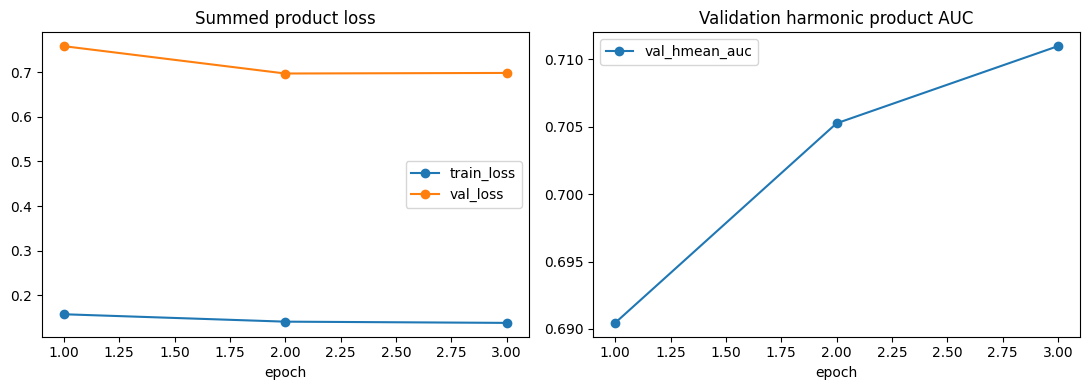

In [66]:
res_exp2_2 = run_experiment(
    exp_name="bigru_attention",
    cat_cols=exp1_2_cats,
    cont_cols=exp1_2_conts,
    model_class=MultiHeadAttentionGRU,
    epochs=EPOCHS
)

# Эксперемент №3.1

Дальше я попробую поменять лосс, на лосс из лекции FocalLoss который из за дисбаланса класса должен тут подойти, как раз и проверим.

In [67]:
def summed_product_focal_loss(logits, target, product, gamma=2.0, alpha=0.75):
    """Sum mean Focal Loss over products present in a step.

    Parameters
    ----------
    logits, target : torch.Tensor
        Aligned one-dimensional model outputs and binary labels.
    product : torch.Tensor
        Integer product-head index for every row.

    Returns
    -------
    torch.Tensor
        Scalar ``sum_p mean(BCE_i | product_i=p)``.
    """
    if not (logits.ndim == target.ndim == product.ndim == 1):
        raise ValueError("logits, target и product должны быть векторами")
    if not (len(logits) == len(target) == len(product)) or len(logits) == 0:
        raise ValueError("Векторы loss должны иметь одну ненулевую длину")
    bce = nn.functional.binary_cross_entropy_with_logits(
        logits, target, reduction="none"
    )

    probs = torch.sigmoid(logits)
    p_t = target * probs + (1.0 - target) * (1.0 - probs)
    focal_weight = (1.0 - p_t) ** gamma

    alpha_t = target * alpha + (1.0 - target) * (1.0 - alpha)
    
    element_loss = alpha_t * focal_weight * bce
    
    product_losses = [element_loss[product == index].mean()
                      for index in torch.unique(product, sorted=True)]
    return torch.stack(product_losses).sum()

Эксперимент: focal_loss
Epoch 1/3
Epoch 1/3: train_loss=0.0232, val_loss=2.0231, val_hmean_auc=0.685196
Epoch 2/3
Epoch 2/3: train_loss=0.0213, val_loss=1.8248, val_hmean_auc=0.697016
Epoch 3/3
Epoch 3/3: train_loss=0.0207, val_loss=1.7527, val_hmean_auc=0.704736
focal_loss итоги:
Test H-AUC:     0.712729
CatBoost H-AUC: 0.721359
Diff: -0.008630 (Ниже бустинга)


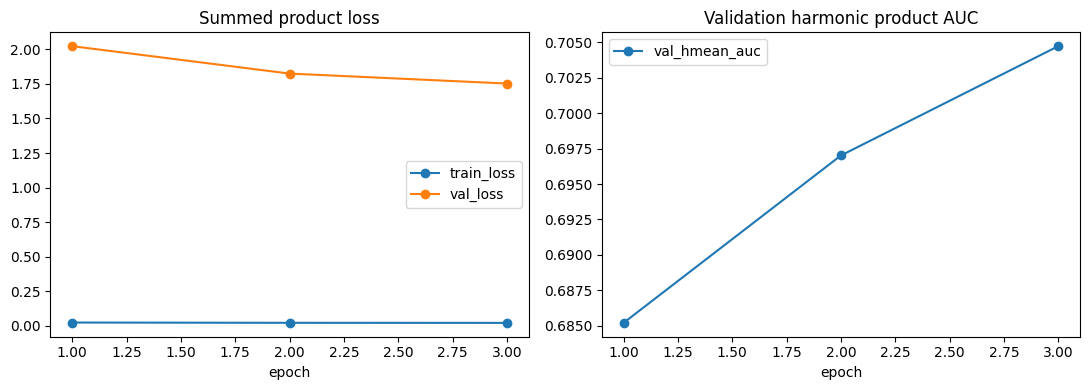

In [69]:
res_exp3_1 = run_experiment(
    exp_name="focal_loss",
    cat_cols=exp1_2_cats,
    cont_cols=exp1_2_conts,
    model_class=MultiHeadAttentionGRU,
    epochs=EPOCHS,
    loss_fn=summed_product_focal_loss
)

Стало не лучше убираем

# Эксперемент №3.2

Увеличим количество эпох и hidden=128

Эксперимент: hidden=128_epochs=6
Epoch 1/6
Epoch 1/6: train_loss=0.1583, val_loss=0.7689, val_hmean_auc=0.667270
Epoch 2/6
Epoch 2/6: train_loss=0.1431, val_loss=0.6976, val_hmean_auc=0.690614
Epoch 3/6
Epoch 3/6: train_loss=0.1390, val_loss=0.7093, val_hmean_auc=0.701951
Epoch 4/6
Epoch 4/6: train_loss=0.1408, val_loss=0.6956, val_hmean_auc=0.701688
Epoch 5/6
Epoch 5/6: train_loss=0.1369, val_loss=0.6908, val_hmean_auc=0.706340
Epoch 6/6
Epoch 6/6: train_loss=0.1351, val_loss=0.7265, val_hmean_auc=0.710132
hidden=128_epochs=6 итоги:
Test H-AUC:     0.712017
CatBoost H-AUC: 0.721359
Diff: -0.009342 (Ниже бустинга)


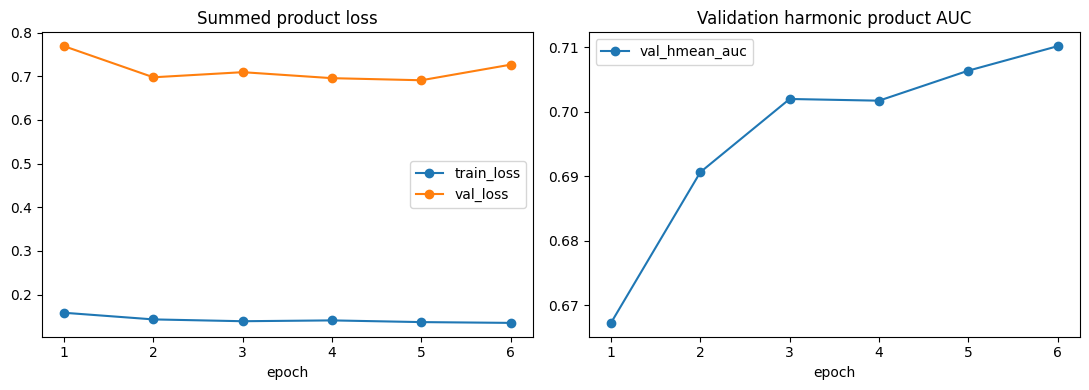

In [71]:
res_exp3_1 = run_experiment(
    exp_name="hidden=128_epochs=6",
    cat_cols=exp1_2_cats,
    cont_cols=exp1_2_conts,
    model_class=MultiHeadAttentionGRU,
    model_kwargs={"emb_dim": 16,"hidden": 128},
    epochs=6,
    batch_size=128
)

# Вывод
В резульате решения задачи многопродуктового кредитного скоринга нам удалось побить результат градиентного бустинга целевой метрики harmonic mean ROC-AUC с помощью LSTM модели. Было проведенно много эксперементов для наблюдения изменения целевой метрики от разных воздейсвтий при помощи Permutation Importance я убрал признаки с наименьшим влияние для ускорения инференса. Дальше были эксперементы с архитектурой, где итоговая модель использовала механизм внимания и GRU - быстрая версия LSTM. Данная реализация показала большой рост скора, за счет уменьшения затухание градиента на длинных цепочках. Дальше были попытки подобрать оптимальные гиперпараметры. Для улучшения можно было реализовать архитекутру Transformer и возможно объединить резульататы с бустингом. Также думаю есть множество оптимизаций для обучения, которые бы улучшили результат.